# PARTIE I

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
#from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
df = pd.read_csv("/mnt/c/Users/FlavieHIEN/Documents/memoire_master/extraction_preparation/normalisation/fiabilisation/nominations_2015_2025_fiabilise.csv", sep=';')
df.shape

In [5]:
# Conserver uniquement les colonnes utiles, dans cet ordre.
colonnes_a_conserver = ['date_conseil', 'id_personne', 'civilite', 'nom', 'matricule', 'emploi', 'grade', 'classe', 'echelon', 'fonction', 'poste_nomination', 'ministere_harmonise']
df = df.loc[:, colonnes_a_conserver].copy()
df.head()


,date_conseil,id_personne,civilite,nom,matricule,emploi,grade,classe,echelon,fonction,poste_nomination,ministere_harmonise
0,26/02/2020,8986.0,Monsieur,Komikiyoaba NALKESSE,91 973 M,Conseiller en économie et développement,NaN,1ère classe,6ème échelon,nommé,nommé,PRESIDENCE DU FASO
1,26/02/2020,11737.0,Monsieur,Marcel OUEDRAOGO,217 041 T,Conseiller en gestion des ressources humaines,NaN,1ère classe,5ème échelon,Membre suppléant,Membre suppléant,PRESIDENCE DU FASO
2,26/02/2020,15055.0,Monsieur,Sibiri COULIBALY,NaN,"Officier, Colonel-major",NaN,NaN,NaN,Directeur des plans et des opérations,Directeur des plans et des opérations,"MINISTERE DE L'ADMINISTRATION TERRITORIALE, DE..."
3,26/02/2020,15824.0,Monsieur,Boubakar KEITA,NaN,"Officier, Commandant",NaN,NaN,NaN,Directeur de la prévention et de la règlementa...,Directeur de la prévention et de la règlementa...,"MINISTERE DE L'ADMINISTRATION TERRITORIALE, DE..."
4,26/02/2020,8600.0,Monsieur,Cebastien SAWADOGO,227 567 N,Commissaire principal de police,NaN,1ère classe,1er échelon,Directeur provincial de la police nationale du...,Directeur provincial de la police nationale du...,MINISTERE DE LA SECURITE


In [6]:
# Supprimer les lignes dont la date du conseil est en 2010
masque_2010 = pd.to_datetime(df["date_conseil"], errors="coerce").dt.year.eq(2010)
nb_lignes_supprimees = int(masque_2010.sum())
df = df.loc[~masque_2010].copy()

print(f"Nombre de lignes supprimées (année 2010) : {nb_lignes_supprimees}")
df.head()

Nombre de lignes supprimées (année 2010) : 0


/tmp/ipykernel_3919/3539399372.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  masque_2010 = pd.to_datetime(df["date_conseil"], errors="coerce").dt.year.eq(2010)


,date_conseil,id_personne,civilite,nom,matricule,emploi,grade,classe,echelon,fonction,poste_nomination,ministere_harmonise
0,26/02/2020,8986.0,Monsieur,Komikiyoaba NALKESSE,91 973 M,Conseiller en économie et développement,NaN,1ère classe,6ème échelon,nommé,nommé,PRESIDENCE DU FASO
1,26/02/2020,11737.0,Monsieur,Marcel OUEDRAOGO,217 041 T,Conseiller en gestion des ressources humaines,NaN,1ère classe,5ème échelon,Membre suppléant,Membre suppléant,PRESIDENCE DU FASO
2,26/02/2020,15055.0,Monsieur,Sibiri COULIBALY,NaN,"Officier, Colonel-major",NaN,NaN,NaN,Directeur des plans et des opérations,Directeur des plans et des opérations,"MINISTERE DE L'ADMINISTRATION TERRITORIALE, DE..."
3,26/02/2020,15824.0,Monsieur,Boubakar KEITA,NaN,"Officier, Commandant",NaN,NaN,NaN,Directeur de la prévention et de la règlementa...,Directeur de la prévention et de la règlementa...,"MINISTERE DE L'ADMINISTRATION TERRITORIALE, DE..."
4,26/02/2020,8600.0,Monsieur,Cebastien SAWADOGO,227 567 N,Commissaire principal de police,NaN,1ère classe,1er échelon,Directeur provincial de la police nationale du...,Directeur provincial de la police nationale du...,MINISTERE DE LA SECURITE


In [7]:
# Normalisation de la colonne civilite
import re
import unicodedata

def normaliser_civilite(valeur):
    if pd.isna(valeur) or not str(valeur).strip():
        return pd.NA
    texte = str(valeur).strip()
    cle = "".join(c for c in unicodedata.normalize("NFKD", texte.casefold())
                  if not unicodedata.combining(c))
    cle = re.sub(r"[\s.]+", "", cle)
    return {
        "m": "Monsieur", "mr": "Monsieur", "monsieur": "Monsieur",
        "monsioeur": "Monsieur", "mme": "Madame", "madame": "Madame",
        "mlle": "Mademoiselle", "mademoiselle": "Mademoiselle",
    }.get(cle, texte)

if "civilite" not in df.columns:
    raise ValueError("Rechargez le CSV et conservez civilite dans colonnes_a_conserver.")
df["civilite"] = df["civilite"].map(normaliser_civilite).astype("string")
df["civilite"].value_counts(dropna=False)


civilite
Monsieur        19477
Madame           3608
<NA>               97
Mademoiselle        1
Name: count, dtype: int64[pyarrow]

In [ ]:
# Évolution annuelle par sexe (déduit de la civilité)
from IPython.display import display

donnees_evolution = df.copy()
donnees_evolution["date_conseil"] = pd.to_datetime(
    donnees_evolution["date_conseil"], errors="coerce"
)
donnees_evolution = donnees_evolution.loc[
    donnees_evolution["date_conseil"].notna()
    & donnees_evolution["poste_nomination"].astype("string").fillna("").str.strip().ne("")
].copy()
donnees_evolution["annee"] = donnees_evolution["date_conseil"].dt.year
donnees_evolution["sexe"] = (
    donnees_evolution["civilite"].astype("string").str.strip().str.casefold()
    .map({"monsieur": "Masculin", "madame": "Féminin", "mademoiselle": "Féminin"})
    .fillna("Non renseigné")
)
donnees_evolution["ministere_analyse"] = (
    donnees_evolution["ministere"].astype("string").fillna("").str.strip()
    .replace("", "Ministère non renseigné")
)
annees_evolution = range(
    int(donnees_evolution["annee"].min()),
    int(donnees_evolution["annee"].max()) + 1,
) if not donnees_evolution.empty else []
sexes_evolution = ["Masculin", "Féminin", "Non renseigné"]
annuel_sexe = (
    donnees_evolution.groupby(["annee", "sexe"]).size().unstack(fill_value=0)
    .reindex(index=annees_evolution, columns=sexes_evolution, fill_value=0)
)
display(annuel_sexe)
if not annuel_sexe.empty:
    ax = annuel_sexe.plot(marker="o", figsize=(12, 5))
    ax.set(title="Évolution annuelle des nominations par sexe déduit de la civilité",
           xlabel="Année", ylabel="Nombre de nominations")
    ax.set_xticks(list(annees_evolution))
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
print("Une ligne = une nomination candidate avec poste renseigné ; pas une personne distincte.")


In [ ]:
# Évolution annuelle par ministère
annuel_ministere = (
    donnees_evolution.groupby(["annee", "ministere_analyse"]).size().unstack(fill_value=0)
    .reindex(index=annees_evolution, fill_value=0)
)
# Tableau complet ; graphique limité pour garder une légende lisible.
# Modifier cette liste pour afficher les ministères de votre choix.
ministeres_a_afficher = (
    donnees_evolution["ministere_analyse"].value_counts().head(10).index.tolist()
)
display(annuel_ministere)
if ministeres_a_afficher:
    ax = annuel_ministere[ministeres_a_afficher].plot(marker="o", figsize=(14, 6))
    ax.set(title="Évolution annuelle — 10 ministères les plus fréquents",
           xlabel="Année", ylabel="Nombre de nominations")
    ax.set_xticks(list(annees_evolution))
    ax.legend(title="Ministère", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
print("Libellés de la colonne ministere : les changements d'intitulés restent distincts.")


,annee,ministere_analyse,sexe,nombre_nominations
0,2015,Artistes-interprètes ou exécutants,Masculin,1
1,2015,Association professionnelle des sociétés d’ass...,Masculin,1
2,2015,Auteurs compositeurs d’œuvres musicales modernes,Masculin,1
3,2015,Auteurs compositeurs d’œuvres musicales tradit...,Masculin,1
4,2015,Auteurs de logiciels et de programmes d’ordina...,Masculin,1
...,...,...,...,...
2308,2025,"ministère des Sports, de la jeunesse et de l’e...",Masculin,7
2309,2025,"ministère des Sports, de la jeunesse et de l’e...",Masculin,1
2310,2025,personnel,Masculin,2
2311,2025,représentants de la commune de Ouagadougou,Féminin,1


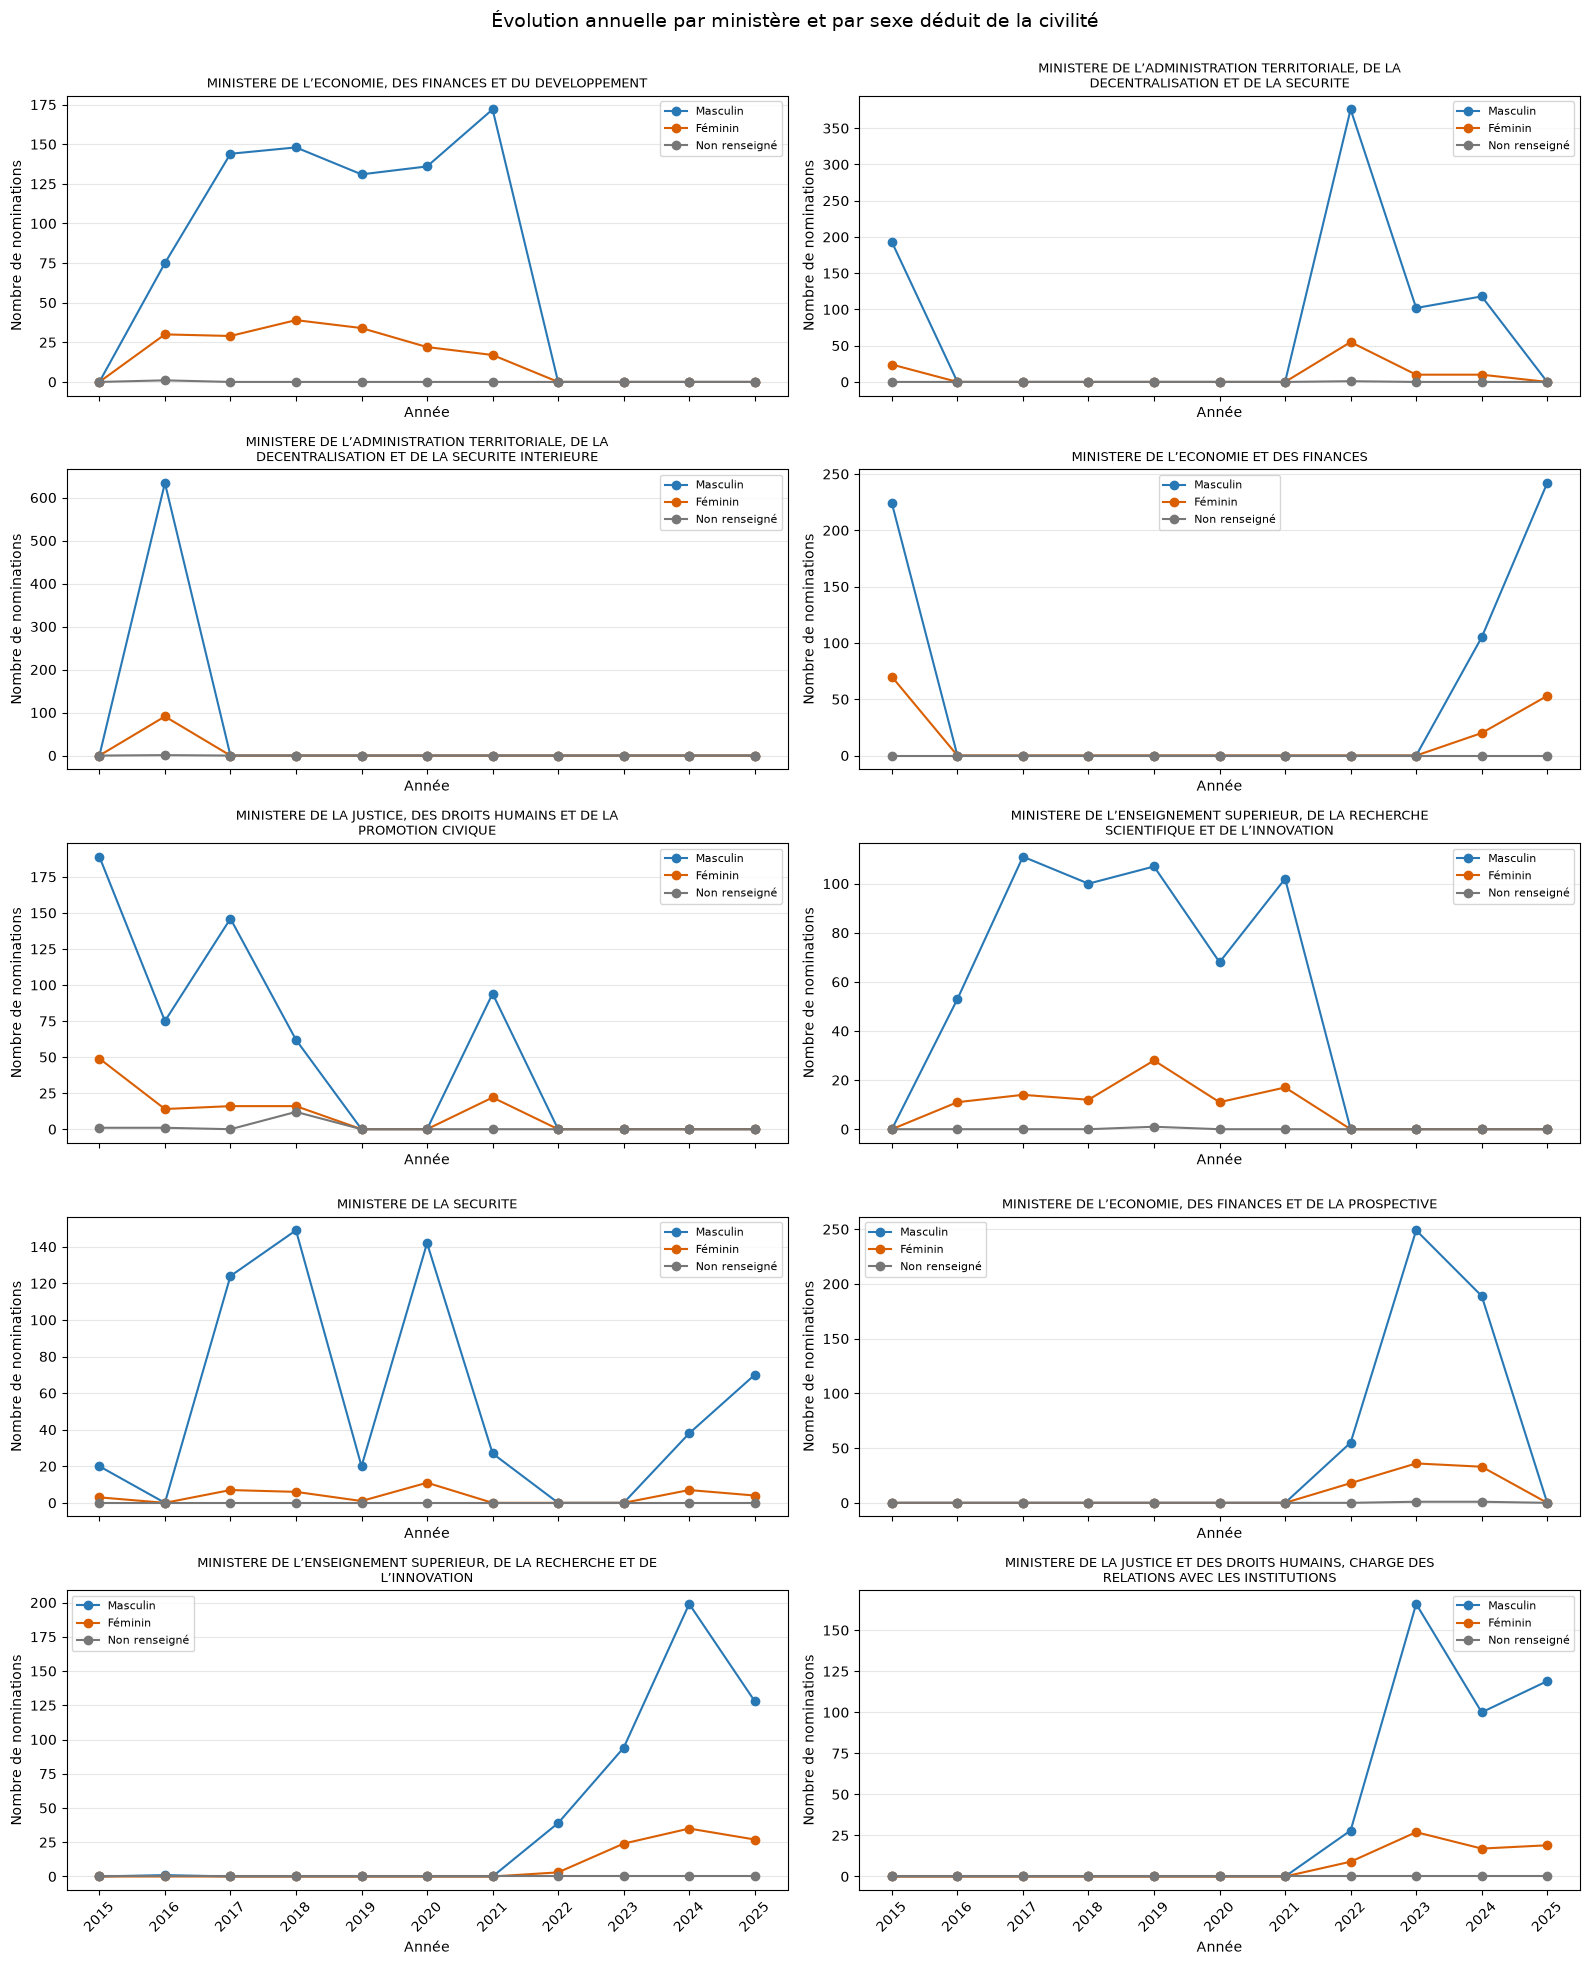

In [8]:
# Évolution annuelle par ministère et par sexe
annuel_ministere_sexe = (
    donnees_evolution.groupby(["annee", "ministere_analyse", "sexe"])
    .size().rename("nombre_nominations").reset_index()
)
display(annuel_ministere_sexe)
# Un panneau par ministère, avec les mêmes ministères que dans le graphique précédent.
if ministeres_a_afficher:
    import math
    nb_colonnes = 2
    nb_lignes = math.ceil(len(ministeres_a_afficher) / nb_colonnes)
    fig, axes = plt.subplots(nb_lignes, nb_colonnes,
                             figsize=(16, 4 * nb_lignes), squeeze=False, sharex=True)
    couleurs_sexe = {"Masculin": "#2878b5", "Féminin": "#d95f02", "Non renseigné": "#777777"}
    for ax, ministere in zip(axes.flat, ministeres_a_afficher):
        tableau = (
            donnees_evolution.loc[donnees_evolution["ministere_analyse"].eq(ministere)]
            .groupby(["annee", "sexe"]).size().unstack(fill_value=0)
            .reindex(index=annees_evolution, columns=sexes_evolution, fill_value=0)
        )
        for sexe in sexes_evolution:
            ax.plot(tableau.index, tableau[sexe], marker="o", label=sexe, color=couleurs_sexe[sexe])
        import textwrap
        ax.set_title(textwrap.fill(ministere, width=60), fontsize=9)
        ax.set_xlabel("Année")
        ax.set_ylabel("Nombre de nominations")
        ax.set_xticks(list(annees_evolution))
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.3)
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(ministeres_a_afficher):]:
        ax.set_visible(False)
    fig.suptitle("Évolution annuelle par ministère et par sexe déduit de la civilité", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


In [9]:
df.dtypes

date_conseil           str
id_personne          int64
civilite            string
nom                    str
matricule              str
emploi                 str
grade                  str
classe                 str
echelon                str
fonction               str
poste_nomination       str
ministere              str
dtype: object

In [10]:
# Exclure les lignes sans poste : elles ne correspondent pas à une nomination.
poste_present = df["poste_nomination"].astype("string").str.strip().fillna("").ne("")
nb_sans_poste = int((~poste_present).sum())
df = df.loc[poste_present].copy()
print(f"Nombre de lignes supprimées sans poste de nomination : {nb_sans_poste}")

# Ajouter des identifiants numériques sans modifier les colonnes d'origine.
# id_personne : un identifiant par couple (nom, matricule).
# id_poste : un identifiant par intitulé de poste_nomination.
noms_normalises = (
    df["nom"].fillna("").astype(str)
    .str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
)
matricules_normalises = (
    df["matricule"].fillna("").astype(str)
    .str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
)
cles_personnes = pd.MultiIndex.from_arrays(
    [noms_normalises, matricules_normalises]
)
codes_personnes, _ = pd.factorize(cles_personnes, sort=True)
df["id_personne"] = codes_personnes + 1

postes_normalises = (
    df["poste_nomination"].astype("string")
    .str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
)
codes_postes, _ = pd.factorize(postes_normalises, sort=True)
df["id_poste"] = codes_postes + 1

print(f"Nombre de personnes : {df['id_personne'].nunique()}")
print(f"Nombre de postes : {df['id_poste'].nunique()}")
df.head()

Nombre de lignes supprimées sans poste de nomination : 0
Nombre de personnes : 14246
Nombre de postes : 12805


,date_conseil,id_personne,civilite,nom,matricule,emploi,grade,classe,echelon,fonction,poste_nomination,ministere,id_poste
0,2020-02-26,7069,Monsieur,Komikiyoaba NALKESSE,91 973 M,Conseiller en économie et développement,NaN,1ère classe,6ème échelon,nommé,nommé,PRESIDENCE DU FASO,10244
1,2020-02-26,8207,Monsieur,Marcel OUEDRAOGO,217 041 T,Conseiller en gestion des ressources humaines,NaN,1ère classe,5ème échelon,Membre suppléant,Membre suppléant,PRESIDENCE DU FASO,10106
2,2020-02-26,11681,Monsieur,Sibiri COULIBALY,NaN,"Officier, Colonel-major",NaN,NaN,NaN,Directeur des plans et des opérations,Directeur des plans et des opérations,"MINISTERE DE L’ADMINISTRATION TERRITORIALE, DE...",5066
3,2020-02-26,2509,Monsieur,Boubakar KEITA,NaN,"Officier, Commandant",NaN,NaN,NaN,Directeur de la prévention et de la règlementa...,Directeur de la prévention et de la règlementa...,"MINISTERE DE L’ADMINISTRATION TERRITORIALE, DE...",4403
4,2020-02-26,2983,Monsieur,Cebastien SAWADOGO,227 567 N,Commissaire principal de police,NaN,1ère classe,1er échelon,Directeur provincial de la police nationale du...,Directeur provincial de la police nationale du...,MINISTERE DE LA SECURITE,6566


In [11]:
# Copie du DataFrame
data = df.copy()

# Conversion en datetime
data["date_conseil"] = pd.to_datetime(
    data["date_conseil"], errors="coerce"
)

# Supprimer les dates invalides
data = data.dropna(subset=["date_conseil"])

# Trier chronologiquement
data = data.sort_values("date_conseil")

# Créer une série mensuelle
serie = (
    data
    .set_index("date_conseil")
    .resample("ME")
    .size()
)

print(serie.head(10))

date_conseil
2015-01-31    526
2015-02-28    284
2015-03-31    603
2015-04-30    105
2015-05-31    156
2015-06-30     72
2015-07-31    305
2015-08-31     47
2015-09-30    102
2015-10-31    214
Freq: ME, dtype: int64


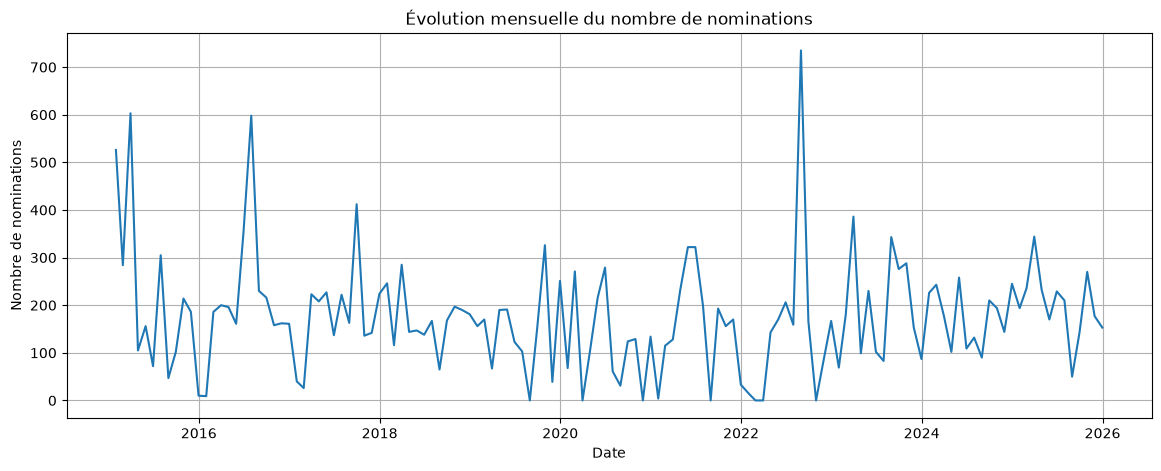

In [12]:
#Visualisation de la série temporelle
plt.figure(figsize=(14, 5))

plt.plot(serie)

plt.title("Évolution mensuelle du nombre de nominations")
plt.xlabel("Date")
plt.ylabel("Nombre de nominations")
plt.grid(True)

plt.show()

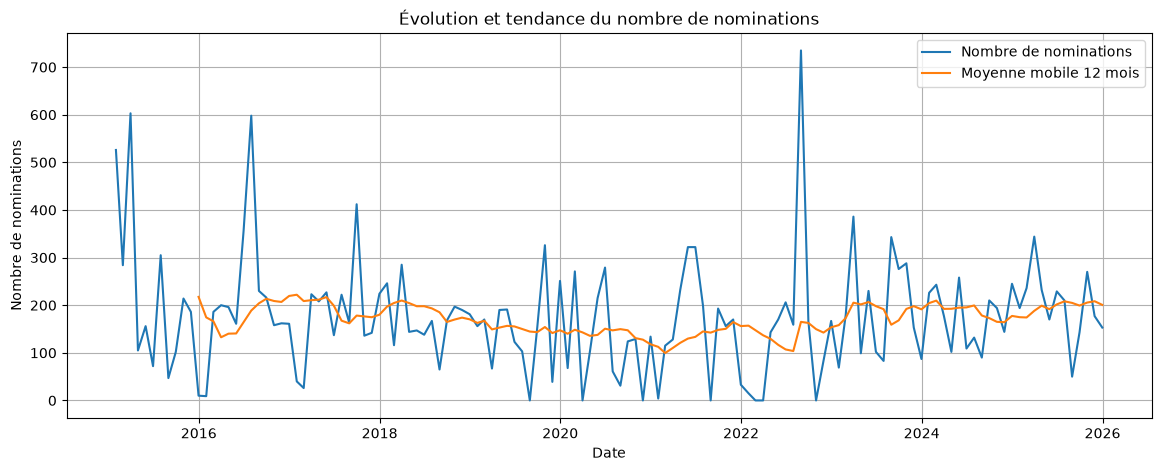

In [13]:
# Moyenne  sur 12 mois
serie_ma12 = serie.rolling(window=12).mean()

plt.figure(figsize=(14, 5))

plt.plot(serie, label="Nombre de nominations")
plt.plot(serie_ma12, label="Moyenne mobile 12 mois")

plt.title("Évolution et tendance du nombre de nominations")
plt.xlabel("Date")
plt.ylabel("Nombre de nominations")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Globalement, la serie semble présenter une tendance globalement constante et une fluctuation saisonnière. Il est donc pertinent de décomposer la série pour mieux comprendre ses composantes.

In [14]:
# Regrouper les nominations par année
nominations_annuelles = (
    data
    .set_index("date_conseil")
    .resample("YE")
    .size()
)

print(nominations_annuelles)

date_conseil
2015-12-31    2610
2016-12-31    2633
2017-12-31    2160
2018-12-31    2044
2019-12-31    1769
2020-12-31    1415
2021-12-31    1874
2022-12-31    1844
2023-12-31    2296
2024-12-31    2130
2025-12-31    2408
Freq: YE-DEC, dtype: int64


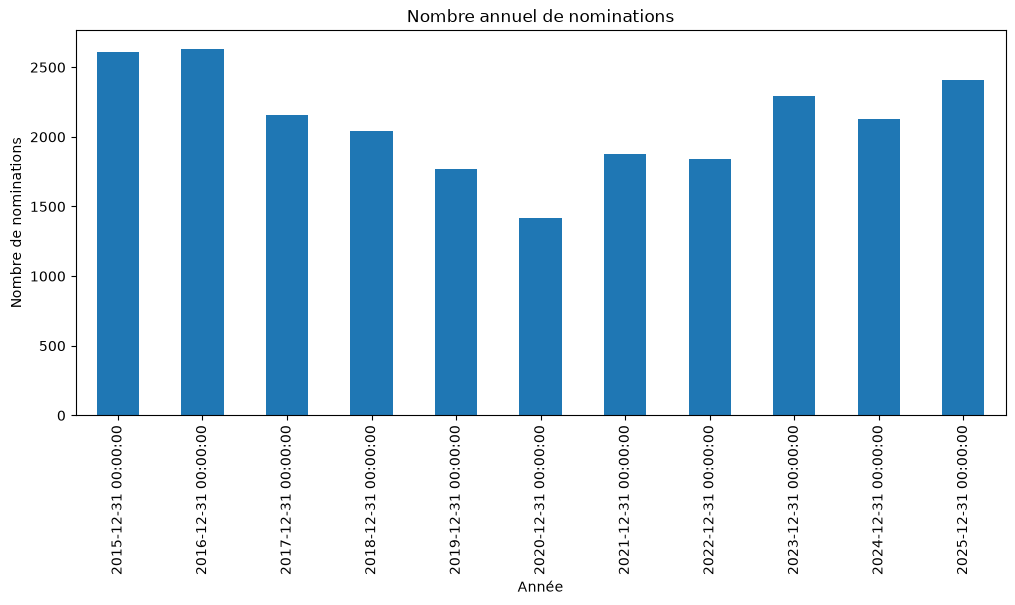

In [15]:
#Puis visualiser les nominations annuelles
nominations_annuelles.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Nombre annuel de nominations")
plt.xlabel("Année")
plt.ylabel("Nombre de nominations")

plt.show()

#### Analyse de la saisonnalite

In [16]:
data["mois"] = data["date_conseil"].dt.month

moyenne_mensuelle = (
    data.groupby("mois")
    .size()
)

print(moyenne_mensuelle)

mois
1     1553
2     1827
3     2413
4     1754
5     2247
6     2073
7     2239
8     1754
9     2163
10    2068
11    1446
12    1646
dtype: int64


In [17]:
moyenne_mensuelle = (
    serie
    .groupby(serie.index.month)
    .mean()
)

print(moyenne_mensuelle)

date_conseil
1     141.181818
2     166.090909
3     219.363636
4     159.454545
5     204.272727
6     188.454545
7     203.545455
8     159.454545
9     196.636364
10    188.000000
11    131.454545
12    149.636364
dtype: float64


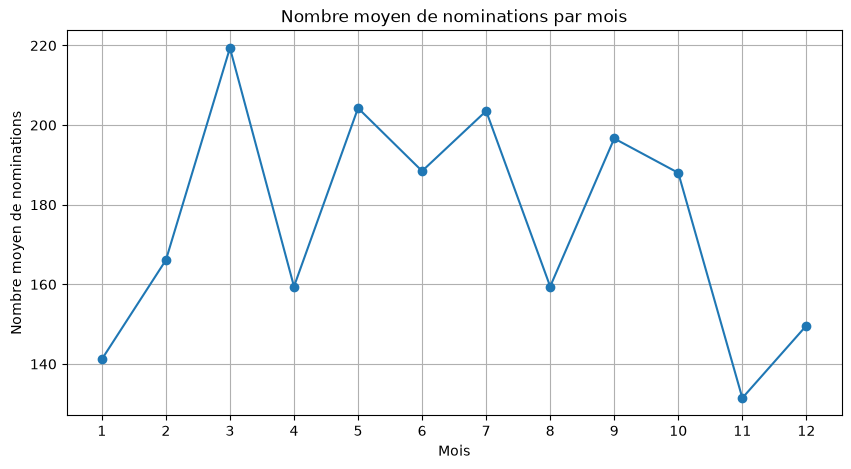

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    moyenne_mensuelle.index,
    moyenne_mensuelle.values,
    marker="o"
)

plt.xticks(range(1, 13))

plt.title("Nombre moyen de nominations par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre moyen de nominations")

plt.grid(True)
plt.show()

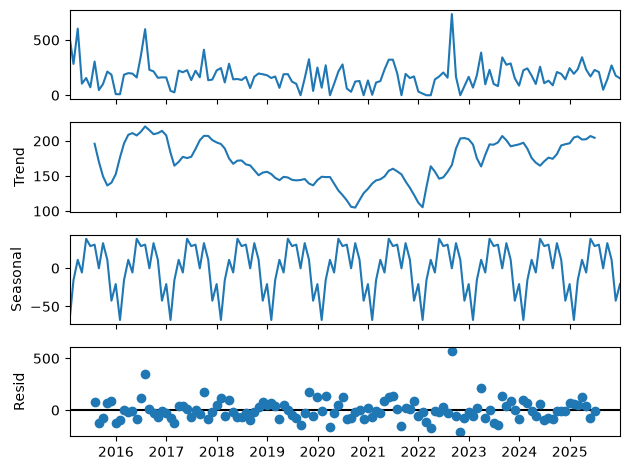

In [19]:
decomposition = seasonal_decompose(
    serie,
    model="additive",
    period=12
)

decomposition.plot()

plt.show()

In [ ]:
# Le nombre de nominations semble presenter d'une maniere globale une tendance constante avec une fluctuation saisonniere. Les residus etant proche de zero, on peut en conclure que le modele est bien ajuste. Il est donc pertinent de faire un test de stationnarité pour confirmer cette hypothese.

In [20]:
# Verification de la stationnarité avec le test ADF
resultat_adf = adfuller(serie.dropna())

print("Statistique ADF :", resultat_adf[0])
print("p-value :", resultat_adf[1])

Statistique ADF : -10.066451857626054
p-value : 1.2924586322281099e-17


/tmp/ipykernel_217653/816724772.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultat_adf = adfuller(serie.dropna())


##### p-value<0.05 donc la serie est consideree comme stationnaire

In [21]:
# Test de KPSS
kpss_test = kpss(serie, regression='c', nlags=12)
print("KPSS p-value :", kpss_test[1])  

KPSS p-value : 0.1


/tmp/ipykernel_217653/2993875249.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_test = kpss(serie, regression='c', nlags=12)
/tmp/ipykernel_217653/2993875249.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_test = kpss(serie, regression='c', nlags=12)


In [ ]:
# La p-value est supérieure à 0.05, ce qui confirme que la série temporelle est stationnaire.

In [ ]:
### Etudions les dependances temporelles

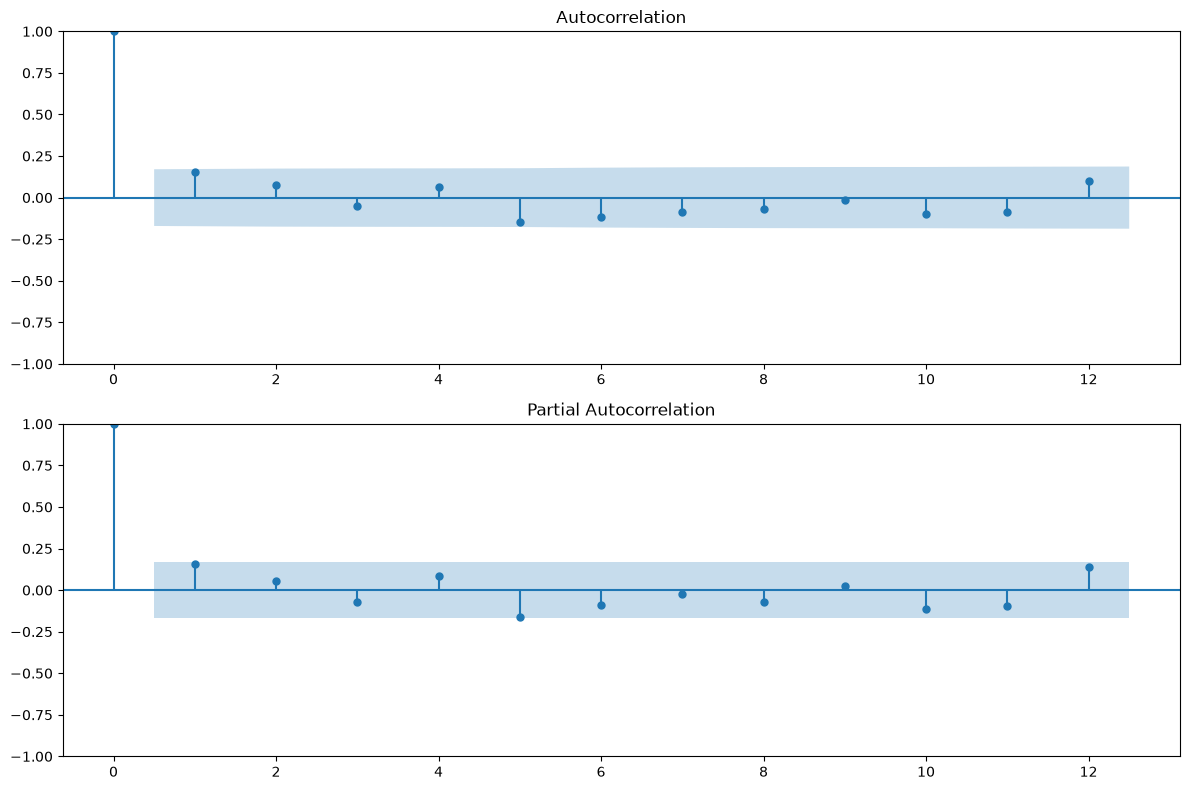

In [22]:
fig = plt.figure(figsize=(12, 8))

plot_acf(
    serie,
    lags=12,
    ax=fig.add_subplot(211)
)

plot_pacf(
    serie,
    lags=12,
    ax=fig.add_subplot(212)
)

plt.tight_layout()
plt.show()

In [ ]:
# Etant donne que les observations ne depassent pas l'intervalle de confiance, il n'y a pas d'autocorelation

In [23]:
#Detection des anomalies dans la série temporelle
residus = decomposition.resid.dropna()

seuil = 3 * residus.std()

anomalies = residus[
    abs(residus) > seuil
]

print(anomalies)

date_conseil
2016-07-31    346.586806
2022-08-31    569.545139
Name: resid, dtype: float64


In [ ]:
#### La periode de 2015-03-31 presente un comportement inhabituel par rapport au reste de la serie

In [25]:
# Prevision avec ARIMA
#model = ARIMA(
#    serie,
#    order=(0, 0, 2),
#)

#resultat = model.fit()

#print(resultat.summary())

# PARTIE II
# 1.	Représenter facilement plusieurs séquences temporelles
# 2.	Découvrir des trajectoires similaires
# 3.	Découvrir des motifs temporels
# 4.	Filtrer des populations selon des critères temporels
# 5.	Exploiter les trajectoires avec du Machine Learning

In [43]:
# Liste des importations nécessaires

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random
from datetime import datetime
import polars as pl
from collections import Counter

#Data simulation
#from tanat.dataset.simulation import (
#    generate_event_sequences,
#    generate_state_sequences,
#    generate_interval_sequences,
#)

# Sequence pools
from tanat.sequence import (
    EventSequencePool,
    StateSequencePool,
    IntervalSequencePool,
    EventSequenceSettings,
    StateSequenceSettings
)

from tanat.visualization.sequence import SequenceVisualizer

# Criterion for filtering
from tanat.criterion import (
    EntityCriterion,
    PatternCriterion,
    TimeCriterion,
    LengthCriterion,
    StaticCriterion,
)

from tanat.metric.entity import HammingEntityMetric
from tanat.metric.sequence import EditSequenceMetric
from tanat.metric.sequence import LinearPairwiseSequenceMetric
from tanat.clustering import HierarchicalClusterer

In [ ]:
# Chargement des données
data = pd.read_csv("/mnt/c/Users/FlavieHIEN/Documents/memoire_master/Dossier_de_travail/nominations_2015_2025.csv", sep=",")
data["date_conseil"] = pd.to_datetime(data["date_conseil"])
data.head()

,document_id,date_conseil,civilite,nom,matricule,emploi,grade,classe,echelon,ministere,poste_nomination,page,extrait_exact
0,CDM - 2015_01_07.pdf,2015-01-07,Monsieur,Honoré Grégoire KARAMBERY,92 574 D,Inspecteur de sécurité pénitentiaire,1er grade,NaN,5ème échelon,"MINISTERE DE LA JUSTICE, DES DROITS HUMAINS ET...",Directeur général de la garde de sécurité péni...,15,"Monsieur Honoré Grégoire KARAMBERY, Mle 92 574..."
1,CDM - 2015_01_07.pdf,2015-01-07,Monsieur,Alain SANKARA,91 237 C,Administrateur des services financiers,NaN,1ère classe,5ème échelon,"MINISTERE DE LA JUSTICE, DES DROITS HUMAINS ET...",Directeur de l’administration et des finances,15,"Monsieur Alain SANKARA, Mle 91 237 C, Administ..."
2,CDM - 2015_01_07.pdf,2015-01-07,Monsieur,Parbignalé Arsène YODA,NaN,Ingénieur statisticien-économiste du développe...,NaN,NaN,NaN,"MINISTERE DE L’ADMINISTRATION TERRITORIALE, DE...",Secrétaire général de l’Office national d’iden...,15,"Monsieur Parbignalé Arsène YODA, Ingénieur sta..."
3,CDM - 2015_01_07.pdf,2015-01-07,Monsieur,Michel KI,16 263,Commissaire divisionnaire de Police,4ème grade,NaN,2ème échelon,"MINISTERE DE L’ADMINISTRATION TERRITORIALE, DE...",Chargé de missions à la Direction générale de ...,15,"Monsieur Michel KI, Mle 16 263, Commissaire di..."
4,CDM - 2015_01_07.pdf,2015-01-07,Monsieur,Rémi TAÏTA,12 636,Commissaire divisionnaire de Police,4ème grade,NaN,2ème échelon,"MINISTERE DE L’ADMINISTRATION TERRITORIALE, DE...",Chargé de missions à la Direction générale de ...,15,"Monsieur Rémi TAÏTA, Mle 12 636, Commissaire d..."


In [44]:
# Filtrage des personnes ayant au moins 03 nominations
NB_OCC_MIN = 3
counts_by_id = data.groupby("id_personne").count().reset_index()
id_min_occ = counts_by_id.loc[counts_by_id["date_conseil"]>=NB_OCC_MIN, "id_personne"].tolist()
data = data.loc[data["id_personne"].isin(id_min_occ),:]

print(f"Number of individuals {len(id_min_occ)}")
print(f"Database Shape {data.shape}")

Number of individuals 1887
Database Shape (7476, 16)


In [164]:
# 1 Représenter facilement plusieurs séquences temporelles
# Creation d'une base de données de séquences d'événements

In [46]:
# garantir le bon type pour la colonne de date
data["date_conseil"] = pd.to_datetime(data["date_conseil"])

# trier par personne puis par date
data = data.sort_values(["id_personne", "date_conseil"]).reset_index(drop=True)

# création de la colonne de fin = date de la prochaine nomination
data["end_date"] = data.groupby("id_personne")["date_conseil"].shift(-1)

# si personne n'a de prochaine nomination, valeur par défaut
data["end_date"] = data["end_date"].fillna(pd.Timestamp("2025-12-31"))

# garantir que la colonne "poste_nomination" est de type catégoriel
data["poste_nomination"] = pd.Categorical(data["poste_nomination"])
data.head(10)

,document_id,date_conseil,civilite,nom,matricule,emploi,grade,classe,echelon,ministere,poste_nomination,page,extrait_exact,id_personne,id_poste,mois,end_date
0,CDM - 2017_03_09.pdf,2017-03-09,Monsieur,Abdallah GOLO,117 249 A,Professeur d’éducation physique et sportive,NaN,1ère classe,6ème échelon,MINISTERE DES SPORTS ET DES LOISIRS,Directeur des sports de haut niveau,21,"Monsieur Abdallah GOLO, Mle 117 249 A, Profess...",13,4897,3,2019-03-20
1,CDM - 2019_03_20.pdf,2019-03-20,Monsieur,Abdallah GOLO,117 249 A,Professeur d’éducation physique et sportive,NaN,1ère classe,7ème échelon,MINISTERE DES SPORTS ET DES LOISIRS,Chargé de missions,15,"Monsieur Abdallah GOLO, Mle 117 249 A, Profess...",13,2710,3,2022-06-08
2,CDM - 2022_06_16.pdf,2022-06-08,Monsieur,Abdallah GOLO,117 249 A,Professeur d’éducation physique et sportive,NaN,1ère classe,10ème échelon,"MINISTERE DES SPORTS, DE LA JEUNESSE ET DE L’E...",Secrétaire technique de la relève sportive,14,"Monsieur Abdallah GOLO, Mle 117 249 A, Profess...",13,11807,6,2025-12-31
3,CDM - 2015_01_07.pdf,2015-01-07,Monsieur,Abdallah Youssef Chahine TRAORE,53 583 T,Administrateur des services financiers,NaN,1ère classe,6ème échelon,"MINISTERE DE L’AGRICULTURE, DES RESSOURCES HYD...",Directeur de l’administration et des finances,27,"Monsieur Abdallah Youssef Chahine TRAORE, Mle ...",16,4353,1,2017-10-11
4,CDM - 2017_10_11.pdf,2017-10-11,Monsieur,Abdallah Youssef Chahine TRAORE,53 583 T,Administrateur des services financiers,NaN,1ère classe,7ème échelon,"MINISTERE DE L’ECONOMIE, DES FINANCES ET DU DE...",Directeur de l’exécution budgétaire,24,"Monsieur Abdallah Youssef Chahine TRAORE, Mle ...",16,4537,10,2018-12-05
5,CDM - 2018_12_05.pdf,2018-12-05,Monsieur,Abdallah Youssef Chahine TRAORE,53 583 T,NaN,NaN,NaN,NaN,MINISTERE DE L’EAU ET DE L’ASSAINISSEMENT,Administrateur représentant l’Etat au titre du...,16,MINISTERE DE L’EAU ET DE L’ASSAINISSEMENT Le C...,16,857,12,2025-12-31
6,CDM - 2015_01_21.pdf,2015-01-21,Monsieur,Abdel Aziz DAO,20 849 H,Conseiller d’intendance universitaire,NaN,1ère classe,9ème échelon,MINISTERE DE L’EDUCATION NATIONALE ET DE L’ALP...,Conseiller technique,23,"Monsieur Abdel Aziz DAO, Mle 20 849 H, Conseil...",19,3524,1,2015-03-25
7,CDM - 2015_04_25.pdf,2015-03-25,Monsieur,Abdel Aziz DAO,20 849 H,Conseiller d’intendance scolaire et universitaire,NaN,NaN,NaN,MINISTERE DE L’EDUCATION NATIONALE ET DE L’ALP...,Directeur de l’allocation des moyens spécifiqu...,33,"Monsieur Abdel Aziz DAO, Mle 20 849 H, Conseil...",19,4482,3,2015-03-25
8,CDM - 2015_03_25.pdf,2015-03-25,Monsieur,Abdel Aziz DAO,20 849 H,Conseiller d’intendance scolaire et universitaire,NaN,NaN,NaN,MINISTERE DE L’EDUCATION NATIONALE ET DE L’ALP...,Directeur de l’allocation des moyens spécifiqu...,33,"Monsieur Abdel Aziz DAO, Mle 20 849 H, Conseil...",19,4482,3,2017-04-19
9,CDM - 2017_04_19.pdf,2017-04-19,Monsieur,Abdel Aziz DAO,20 849 H,Conseiller d’intendance scolaire,NaN,1ère classe,10ème échelon,"MINISTERE DE LA FONCTION PUBLIQUE, DU TRAVAIL ...",Directeur des marchés publics,21,"Monsieur Abdel Aziz DAO, Mle 20 849 H, Conseil...",19,4795,4,2025-12-31


In [47]:
# Creation de builder pour la base de données de séquences d'états
builder = StateSequencePool.builder(end_value=pd.Timestamp("2025-12-31"))
builder.add_dataframe(
    data,
    id_column="id_personne",
    features=["ministere", "poste_nomination"],
    start_column="date_conseil",
    end_column="end_date",
)
store = builder.build(store_path="/mnt/c/Users/FlavieHIEN/Documents/memoire_master/Dossier_de_travail-Copie/tanat_store_ministere_fonction")

┌─ State SequenceStore
│
│ Step 1/4: Sorting & preparing data
│
│ Step 2/4: Building sequence index
│
│ Step 3/4: Writing entity & time index features
│
│ Step 4/4: Computing & writing metadata
│
└─ Done (1,887 sequences · 7,476 entities · 0.31s)


In [49]:
# Création du pool de séquences d'états
sequence_pool = StateSequencePool(
    store,
    id_column="id_personne",
    start_column="date_conseil",
    end_column="end_date",
    entity_features=["ministere", "poste_nomination"]
)

In [ ]:
print(sequence_pool)

┌────────────────────────────────────────────────┐
│           StateSequencePool Summary            │
└────────────────────────────────────────────────┘

Overview
─────────────────────────
  Sequences          851
  Store              /mnt/c/Users/FlavieHIEN/Documents/memoire_master/Dossier_de_travail/Scripts/tanat_store_ministere_fonction
  id_column          id_personne

Time Index
─────────────────────────
  Type               Datetime(time_unit='us', time_zone=None) [2014-07-24 00:00:00 → 2025-12-17 00:00:00]
  Columns            ['date_conseil', 'end_date']
  t0                 position=0, anchor=start

Entity Features (2)
─────────────────────────
  • fonction            Categorical (272 categories)
  • ministere           String [len 9 → 270]


In [50]:
# Affiche les informations sur le store
sequence_pool.describe()

,id_personne,length,n_unique_entities,temporal_span,mean_duration,median_duration,duration_std,n_transitions
0,13,3,3,3219 days 00:00:00,1073 days 00:00:00,1176 days 00:00:00,294 days 08:11:57.543670,1
1,16,3,3,4011 days 00:00:00,1337 days 00:00:00,1008 days 00:00:00,1118 days 09:38:51.501993,1
2,19,4,3,3997 days 00:00:00,999 days 06:00:00,409 days 12:00:00,1492 days 08:01:40.513697,1
3,22,3,3,2835 days 00:00:00,945 days 00:00:00,890 days 00:00:00,618 days 08:05:41.562250,1
4,34,4,4,3626 days 00:00:00,906 days 12:00:00,883 days 00:00:00,589 days 21:10:21.356670,2
...,...,...,...,...,...,...,...,...
1882,13746,6,4,3535 days 00:00:00,589 days 04:00:00,325 days 12:00:00,751 days 09:41:10.843014,4
1883,13758,3,3,2135 days 00:00:00,711 days 16:00:00,581 days 00:00:00,280 days 19:26:35.881625,1
1884,13763,3,3,3115 days 00:00:00,1038 days 08:00:00,1407 days 00:00:00,775 days 17:57:28.017874,1
1885,13764,6,6,2589 days 00:00:00,431 days 12:00:00,40 days 12:00:00,692 days 19:51:08.268025,4


Person 11667 has 4 positions


VisualizationResult(figure=<Figure size 1000x500 with 1 Axes>)

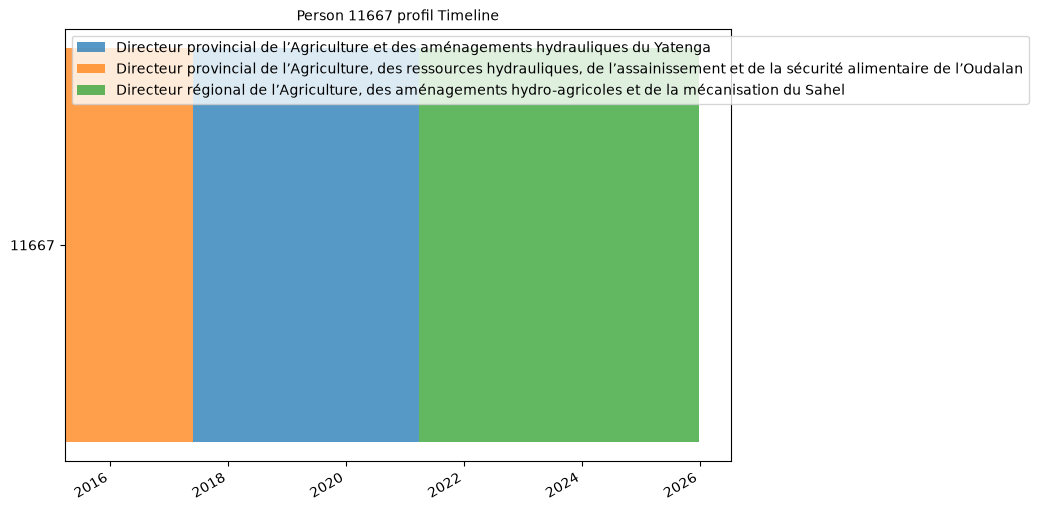

In [51]:
# Visualisation des séquences d'états
# recupération aléatoire d'une personne
index_personne = random.randint(0, len(data)-1)
# recupération de l'id de la personne
id_personne = data["id_personne"].tolist()[index_personne]
# Accès à la séquence de la personne
person_sequence = sequence_pool[id_personne]
print(f"Person {id_personne} has {len(person_sequence)} positions")

# Create visualization
SequenceVisualizer.timeline(
    group_by="id",
    time_mode = 'absolute'
).title(f"Person {id_personne} profil Timeline") \
.draw(person_sequence, entity_feature="poste_nomination") 

In [52]:
frequences_ministeres = (
    sequence_pool
    .temporal_data(features=["ministere"])
    ["ministere"]
    .value_counts()
    .head(20)
    .rename_axis("ministere")
    .reset_index(name="nombre")
)

frequences_ministeres

,ministere,nombre
0,"MINISTERE DE L’ECONOMIE, DES FINANCES ET DU DE...",339
1,MINISTERE DE L’ECONOMIE ET DES FINANCES,292
2,"MINISTERE DE LA JUSTICE, DES DROITS HUMAINS ET...",216
3,"ministère de l’Economie, des finances et du dé...",183
4,"MINISTERE DE L’ENSEIGNEMENT SUPERIEUR, DE LA R...",159
5,"MINISTERE DE L’ECONOMIE, DES FINANCES ET DE LA...",144
6,"MINISTERE DE L’ENSEIGNEMENT SUPERIEUR, DE LA R...",136
7,"MINISTERE DE LA JUSTICE ET DES DROITS HUMAINS,...",136
8,MINISTERE DE LA SANTE,130
9,"MINISTERE DE L’ADMINISTRATION TERRITORIALE, DE...",120


<Axes: xlabel='nombre', ylabel='ministere'>

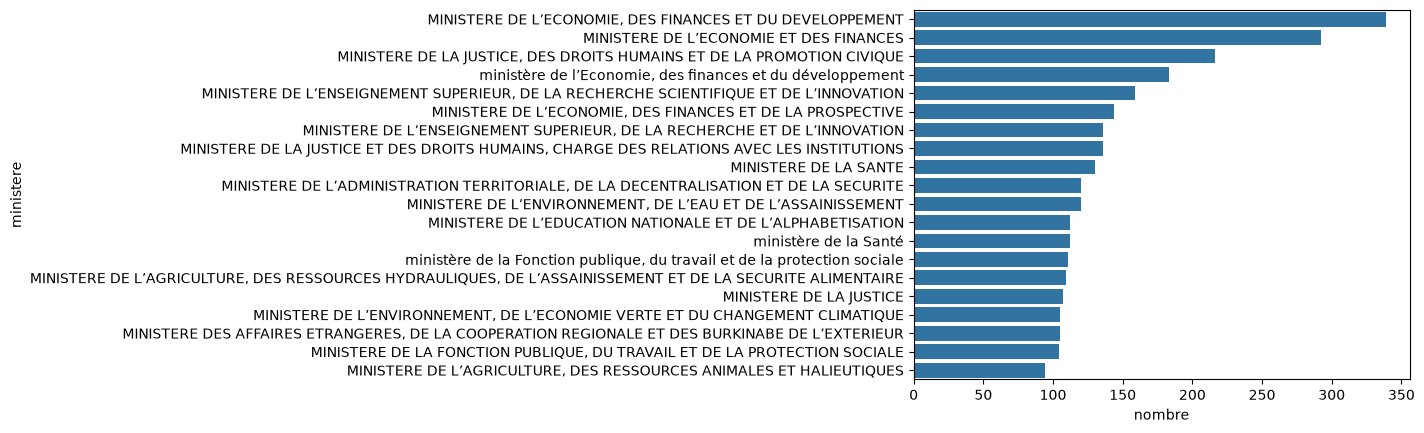

In [53]:
sns.barplot(data=frequences_ministeres, x="nombre", y="ministere")

In [ ]:
# 2. Découvrir des trajectoires similaires
# Il existe des métriques pour comparer les états, les séquences et les trajectoires.
# Dans chacun de ces cas, il y a plusieurs métriques possibles.

In [54]:
# Metriques pour comparer les séquences d'états
# la metrique de distance d'edition (Edit Distance) est une mesure de similarité entre deux séquences. 
# Elle est définie comme le nombre minimum d'opérations nécessaires pour transformer une séquence en une autre.
# Les opérations autorisées sont généralement l'insertion, la suppression et la substitution d'un élément.
hamming = HammingEntityMetric(entity_feature="fonction")
metric1 = EditSequenceMetric(entity_metric=hamming, indel_cost=1.0, normalize=True)
print(metric1)

EditSequenceMetric(settings=EditSettings(entity_metric=HammingEntityMetric(settings=HammingSettings(entity_feature='fonction', cost=None, mismatch_cost=1.0)), indel_cost=1.0, normalize=True))


In [55]:
ids = sequence_pool.unique_ids
dist = metric1(sequence_pool[ids[0]], sequence_pool[ids[1]])
print(f"Distance between {ids[0]} and {ids[1]}: {dist:.4f}")
# le est 1. Ce qui signifie que les deux séquences sont très différentes, car elles n'ont pas de fonction en commun.

KeyError: "Feature 'fonction' not found in entity features."

In [ ]:
# Calcul de la matrice de distance pour toutes les séquences
dm = metric1.compute_matrix(sequence_pool)
print(f"Distance matrix shape: {dm.shape}")

┌─ EditSequenceMetric
│


│ Chunks: 100%|██████████| 1/1 [00:00<00:00, 16.86it/s]

│
└─ Done (851 sequences · 0.10s)
Distance matrix shape: (851, 851)


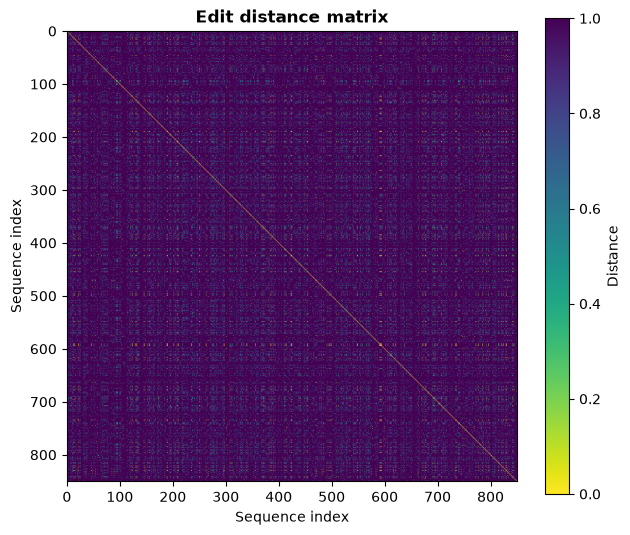

In [ ]:
arr = dm.to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(arr, cmap="viridis_r", vmin=0, vmax=1)
ax.set_title("Matrice de distance d'edition", fontsize=12, fontweight="bold")
ax.set_xlabel("Sequence")
ax.set_ylabel("Sequence")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Distance")
plt.tight_layout()
plt.show()

In [ ]:
# Il serait preferable d'avoir des groupes de sequences...
# Mais si c'est un groupe, comment va t il calculer les distences?

In [ ]:
# la metrique LinearPairwiseSequenceMetric
metric2 = LinearPairwiseSequenceMetric(
    entity_metric=hamming, agg_fun="mean", padding_penalty=1.0
)
print(metric2)

LinearPairwiseSequenceMetric(settings=LinearPairwiseSettings(entity_metric=HammingEntityMetric(settings=HammingSettings(entity_feature='fonction', cost=None, mismatch_cost=1.0)), agg_fun='mean', padding_penalty=1.0))


In [ ]:
# Calculons la distance entre une seule paire
ids = sequence_pool.unique_ids
dist = metric2(sequence_pool[ids[0]], sequence_pool[ids[1]])
print(f"Distance between {ids[0]} and {ids[1]}: {dist:.4f}")


Distance between 6 and 10: 1.0000


In [ ]:
# Appliquer a toutes les sequences
dm = metric2.compute_matrix(sequence_pool)
print(f"Distance matrix shape: {dm.shape}")

┌─ LinearPairwiseSequenceMetric
│


│ Chunks: 100%|██████████| 1/1 [00:00<00:00, 15.36it/s]

│
└─ Done (851 sequences · 0.10s)
Distance matrix shape: (851, 851)


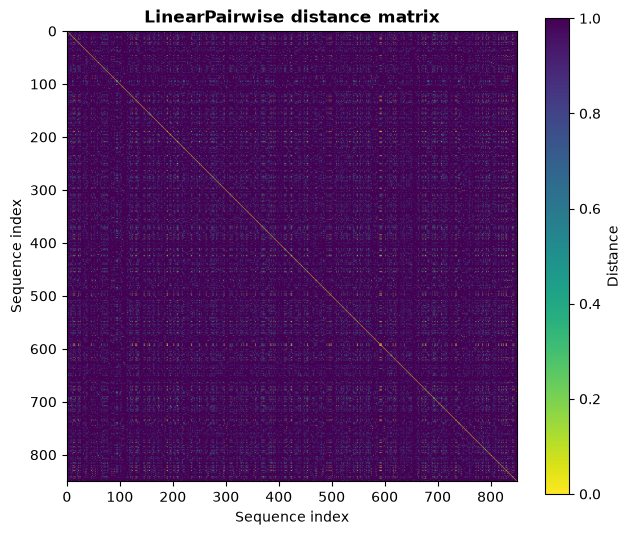

In [ ]:
arr = dm.to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(arr, cmap="viridis_r", vmin=0, vmax=1)
ax.set_title("Matrice de distance LinearPairwise", fontsize=12, fontweight="bold")
ax.set_xlabel("Sequence")
ax.set_ylabel("Sequence")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Distance")
plt.tight_layout()
plt.show()

In [ ]:
# Classifions les sequences
# classification hierarchique
clusterer = HierarchicalClusterer(
    metric=metric1,
    n_clusters=20,
)

clusterer.fit(sequence_pool)

┌─ HierarchicalClusterer
│
│ Step 1/2: Computing distance matrix
│
│   ┌─ EditSequenceMetric
│   │


│   │ Chunks: 100%|██████████| 1/1 [00:00<00:00, 16.30it/s]

│   │
│   └─ Done (851 sequences · 0.11s)
│
│ Step 2/2: Clustering (HierarchicalClusterer)
│
└─ Done (851 items, 20 clusters · 0.33s)


HierarchicalClusterer(clusters=20)

In [ ]:
print(clusterer.clusters)

[Cluster(id=0, size=520), Cluster(id=1, size=101), Cluster(id=2, size=38), Cluster(id=3, size=46), Cluster(id=4, size=29), Cluster(id=5, size=9), Cluster(id=6, size=4), Cluster(id=7, size=10), Cluster(id=8, size=11), Cluster(id=9, size=4), Cluster(id=10, size=2), Cluster(id=11, size=5), Cluster(id=12, size=6), Cluster(id=13, size=3), Cluster(id=14, size=4), Cluster(id=15, size=7), Cluster(id=16, size=9), Cluster(id=17, size=10), Cluster(id=18, size=29), Cluster(id=19, size=4)]


In [ ]:
print(sequence_pool.static_data().head())

   id_personne  __HCLUSTERS__
0            6              0
1           10              0
2           53              0
3           56              0
4           59              0


In [ ]:
# 3 Découvrir des motifs temporels

Index(['id_personne', '__HCLUSTERS__'], dtype='str')


In [ ]:
# Récupérer les séquences
seqs = sequence_pool.get_sequences()
# Récupérer les clusters
static = sequence_pool.static_data()
# Construire les groupes d'ID
groupes = {
    cluster_id: groupe["id_personne"].tolist()
    for cluster_id, groupe in static.groupby("__HCLUSTERS__")
}
# Associer chaque ID à son objet Sequence
groupes_sequences = {
    cluster_id: {
        id_personne: seqs[id_personne]
        for id_personne in ids_cluster
    }
    for cluster_id, ids_cluster in groupes.items()
}
groupes_sequences

{0: {6: StateSequence(id=6, length=3, entity_features=2),
  10: StateSequence(id=10, length=4, entity_features=2),
  53: StateSequence(id=53, length=3, entity_features=2),
  68: StateSequence(id=68, length=3, entity_features=2),
  85: StateSequence(id=85, length=4, entity_features=2),
  90: StateSequence(id=90, length=3, entity_features=2),
  123: StateSequence(id=123, length=3, entity_features=2),
  139: StateSequence(id=139, length=3, entity_features=2),
  169: StateSequence(id=169, length=3, entity_features=2),
  180: StateSequence(id=180, length=3, entity_features=2),
  199: StateSequence(id=199, length=3, entity_features=2),
  253: StateSequence(id=253, length=3, entity_features=2),
  256: StateSequence(id=256, length=3, entity_features=2),
  258: StateSequence(id=258, length=3, entity_features=2),
  278: StateSequence(id=278, length=3, entity_features=2),
  287: StateSequence(id=287, length=3, entity_features=2),
  288: StateSequence(id=288, length=4, entity_features=2),
  315: S

In [ ]:
nb_total = sum(len(groupe) for groupe in groupes_sequences.values())

print("Nombre total de séquences :", nb_total)
print("Nombre de séquences dans pool :", len(seqs))

Nombre total de séquences : 851
Nombre de séquences dans pool : 851


In [ ]:
# Recuperons les donnees du premier cluster
cluster_0 = groupes_sequences[0]
print("Nombre de personnes dans le cluster 0 :", len(cluster_0))

Nombre de personnes dans le cluster 0 : 520


In [ ]:
# Transformons les sequences du cluster 0 en dataframe

donnees_cluster_0 = []

for id_personne, sequence in cluster_0.items():

    df_seq = sequence.temporal_data().copy()

    donnees_cluster_0.append(df_seq)

cluster_0_df = pd.concat(
    donnees_cluster_0,
    ignore_index=True
)
print(cluster_0_df.shape)
print(cluster_0_df.head())

(1780, 5)
   id_personne         date_conseil             end_date  \
0            6  2017-03-09 00:00:00  2019-03-20 00:00:00   
1            6  2019-03-20 00:00:00  2022-06-08 00:00:00   
2            6  2022-06-08 00:00:00  2025-11-05 00:00:00   
3           10  2015-01-21 00:00:00  2015-03-25 00:00:00   
4           10  2015-03-25 00:00:00  2015-03-25 00:00:00   

               fonction                                          ministere  
0      directeur sports                MINISTERE DES SPORTS ET DES LOISIRS  
1       chargé missions                MINISTERE DES SPORTS ET DES LOISIRS  
2  secrétaire technique  MINISTERE DES SPORTS, DE LA JEUNESSE ET DE L'E...  
3  conseiller technique  MINISTERE DE L'EDUCATION NATIONALE ET DE L'ALP...  
4  directeur allocation  MINISTERE DE L'EDUCATION NATIONALE ET DE L'ALP...  


In [ ]:
# Quelles fonction domine dans le premier cluster

fonctions = (
    cluster_0_df["poste_nomination"]
    .value_counts()
)

print(fonctions.head(20))

fonction
directeur général           170
directeur régional          114
conseiller technique         69
responsable programme        68
secrétaire général           62
directeur maison             62
chargé missions              60
chef département             59
inspecteur technique         54
chargé mission               51
premier conseiller           43
vice-président chargé        38
directeur administration     36
chargé études                35
directeur provincial         29
maître conférences           27
agent comptable              26
directeur marchés            24
directeur cabinet            24
secrétaire permanent         24
ministre conseiller          22
professeur titulaire         21
directeur développement      20
inspecteur général           19
directeur affaires           17
directeur promotion          16
deuxième conseiller          16
trésorier auprès             15
directeur ressources         13
directeur coordination       13
Name: count, dtype: int64[pyarr

In [ ]:
# Les fonctions les plus représentées parmi les positions observées dans le cluster 0 en %
pourcentage_fonctions = (
    cluster_0_df["poste_nomination"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(pourcentage_fonctions.head(20))

fonction
directeur général           9.55
directeur régional           6.4
conseiller technique        3.88
responsable programme       3.82
secrétaire général          3.48
directeur maison            3.48
chargé missions             3.37
chef département            3.31
inspecteur technique        3.03
chargé mission              2.87
premier conseiller          2.42
vice-président chargé       2.13
directeur administration    2.02
chargé études               1.97
directeur provincial        1.63
maître conférences          1.52
agent comptable             1.46
directeur marchés           1.35
directeur cabinet           1.35
secrétaire permanent        1.35
Name: proportion, dtype: double[pyarrow]


In [ ]:
# Calculons la duree de chaque fonction
cluster_0_df["duree"] = (
    cluster_0_df["end_date"]
    - cluster_0_df["date_conseil"]
)

In [ ]:
cluster_0_df["duree_jours"] = (
    cluster_0_df["duree"]
    .dt.total_seconds()
    / (24 * 3600)
)

In [ ]:
cluster_0_df["duree_annees"] = (
    cluster_0_df["duree_jours"] / 365.25
)

In [ ]:
duree_par_fonction = (
    cluster_0_df
    .groupby("poste_nomination")["duree_annees"]
    .agg(
        nombre="count",
        duree_totale="sum",
        duree_moyenne="mean",
        duree_mediane="median"
    )
    .sort_values(
        "duree_totale",
        ascending=False
    )
)

print(duree_par_fonction.head(20))

                          nombre  duree_totale  duree_moyenne  duree_mediane
fonction                                                                    
directeur général            170    378.349076       2.225583       1.676934
directeur régional           114    339.110198       2.974651       2.338125
conseiller technique          69    197.508556       2.862443       1.954825
chef département              59    164.714579       2.791773       2.433949
responsable programme         68    151.077344       2.221726       1.685147
chargé missions               60    149.040383       2.484006       2.392882
directeur maison              62    145.344285       2.344263        2.31896
secrétaire général            62     145.32512       2.343954       1.575633
premier conseiller            43    144.804928       3.367556       3.071869
inspecteur technique          54    128.843258       2.385986       1.926078
directeur provincial          29    106.833676        3.68392       2.970568

In [ ]:
# Trier les séquences
cluster_0_df = cluster_0_df.sort_values(
    ["id_personne", "date_conseil"]
).reset_index(drop=True)

# Fonction suivante
cluster_0_df["fonction_suivante"] = (
    cluster_0_df
    .groupby("id_personne")["fonction"]
    .shift(-1)
)

# Supprimer les dernières positions
transitions_df = cluster_0_df.dropna(
    subset=["fonction_suivante"]
).copy()

# Convertir les colonnes PyArrow dictionary en chaînes
transitions_df["poste_nomination"] = (
    transitions_df["poste_nomination"]
)

transitions_df["fonction_suivante"] = (
    transitions_df["fonction_suivante"].astype(str)
)

# Garder uniquement les changements de fonction
transitions_df = transitions_df[
    transitions_df["poste_nomination"]
    != transitions_df["fonction_suivante"]
].copy()

# Construire la transition
transitions_df["transition"] = (
    transitions_df["poste_nomination"]
    + " → "
    + transitions_df["fonction_suivante"]
)

# Fréquence des transitions
transitions_reelles = (
    transitions_df["transition"]
    .value_counts()
)

print(transitions_reelles.head(20))

transition
directeur général → responsable programme       42
directeur régional → directeur général          20
directeur provincial → directeur régional       19
responsable programme → directeur général       17
premier conseiller → ministre conseiller        13
deuxième conseiller → premier conseiller        12
chargé missions → chargé mission                 9
chef département → secrétaire permanent          9
maître conférences → professeur titulaire        8
conseiller technique → directeur général         7
maître conférences → vice-président chargé       7
conseiller technique → chargé missions           7
directeur régional → chargé missions             6
directeur général → secrétaire général           6
chargé missions → conseiller technique           6
responsable programme → conseiller technique     5
inspecteur finances → chef département           5
chargé études → directeur régional               5
chargé missions → inspecteur technique           5
directeur régional →